In [1]:

!pip install -q ultralytics scikit-learn seaborn


import torch

if torch.cuda.is_available():
    print("GPU disponible:", torch.cuda.get_device_name(0))
else:
    print("No hay GPU disponible.")
    print("En Colab: Entorno de ejecución > Cambiar tipo de entorno > T4 GPU")

print("Versión de PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
print("Entorno preparado.")


GPU disponible: Tesla T4
Versión de PyTorch: 2.14.1+cu130
CUDA disponible: True
Entorno preparado.


In [2]:


import os
import json
import random
import shutil
import copy
import warnings

from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import (
    Dataset,
    DataLoader,
    WeightedRandomSampler
)

from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

from ultralytics import YOLO

from google.colab import drive

# Configuración general
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings("ignore")

# Conectar Google Drive
drive.mount('/content/drive')

print("Todas las librerías fueron importadas.")
print("Google Drive conectado correctamente.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Mounted at /content/drive
Todas las librerías fueron importadas.
Google Drive conectado correctamente.


In [3]:


BASE_DIR = Path("/content/drive/MyDrive/Dataset_danzas")


POSE_DIR = BASE_DIR / "dataset_2"


NO_POSE_DIR = BASE_DIR / "dataset_nop"


NEW_TEST_DIR = BASE_DIR / "imagenes_prueba"

KEYPOINT_MODEL_PATH = Path(
    "/content/drive/MyDrive/pose_classifier.pth"
)


KEYPOINT_CSV_PATH = Path(
    "/content/drive/MyDrive/dataset_keypoints.csv"
)


IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 25
LEARNING_RATE = 0.001


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Dispositivo:", DEVICE)
print("Dataset positivo:", POSE_DIR)
print("Dataset negativo:", NO_POSE_DIR)
print("Carpeta de pruebas:", NEW_TEST_DIR)


for carpeta in [POSE_DIR, NO_POSE_DIR]:
    if carpeta.exists():
        print("ENCONTRADA:", carpeta)
    else:
        print("NO ENCONTRADA:", carpeta)

NEW_TEST_DIR.mkdir(parents=True, exist_ok=True)

print("\nConfiguración terminada.")


Dispositivo: cuda
Dataset positivo: /content/drive/MyDrive/Dataset_danzas/dataset_2
Dataset negativo: /content/drive/MyDrive/Dataset_danzas/dataset_nop
Carpeta de pruebas: /content/drive/MyDrive/Dataset_danzas/imagenes_prueba
ENCONTRADA: /content/drive/MyDrive/Dataset_danzas/dataset_2
ENCONTRADA: /content/drive/MyDrive/Dataset_danzas/dataset_nop

Configuración terminada.


In [4]:


EXTENSIONES = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".webp"
}

def obtener_imagenes(carpeta):
    return [
        archivo
        for archivo in carpeta.rglob("*")
        if archivo.is_file()
        and archivo.suffix.lower() in EXTENSIONES
    ]

image_paths_pose = obtener_imagenes(POSE_DIR)
image_paths_no_pose = obtener_imagenes(NO_POSE_DIR)

print("IMÁGENES ENCONTRADAS")
print("----------------------------")
print("Positivas (pose de danza):", len(image_paths_pose))
print("Negativas (sin pose de danza):", len(image_paths_no_pose))
print("Total:", len(image_paths_pose) + len(image_paths_no_pose))

print("\nModelo de puntos clave:")
print("Existe:", KEYPOINT_MODEL_PATH.exists())

print("\nCSV de puntos clave:")
print("Existe:", KEYPOINT_CSV_PATH.exists())

# Verificar que las carpetas no estén vacías
if len(image_paths_pose) == 0:
    print("\nADVERTENCIA: No se encontraron imágenes positivas.")

if len(image_paths_no_pose) == 0:
    print("\nADVERTENCIA: No se encontraron imágenes negativas.")


IMÁGENES ENCONTRADAS
----------------------------
Positivas (pose de danza): 572
Negativas (sin pose de danza): 101
Total: 673

Modelo de puntos clave:
Existe: True

CSV de puntos clave:
Existe: False


In [5]:


SPLIT_DIR = BASE_DIR / "dataset_dividido"

# Comprobar que cada clase tenga suficientes imágenes
if len(image_paths_pose) < 4 or len(image_paths_no_pose) < 4:
    raise ValueError(
        "Cada clase necesita al menos 4 imágenes."
    )

# Dividir una clase en entrenamiento, validación y prueba
def dividir_clase(lista_imagenes, seed=42):

    imagenes = list(lista_imagenes)

    # 70% entrenamiento, 30% temporal
    train, temporal = train_test_split(
        imagenes,
        test_size=0.30,
        random_state=seed
    )

    # Dividir el 30% en validación y prueba
    val, test = train_test_split(
        temporal,
        test_size=0.50,
        random_state=seed
    )

    return train, val, test


# Dividir las dos clases
pose_train, pose_val, pose_test = dividir_clase(
    image_paths_pose
)

nopose_train, nopose_val, nopose_test = dividir_clase(
    image_paths_no_pose
)

# Eliminar la división anterior para evitar imágenes antiguas
if SPLIT_DIR.exists():
    shutil.rmtree(SPLIT_DIR)

# Crear estructura de carpetas
for conjunto in ["train", "val", "test"]:
    for clase in ["pose", "no_pose"]:
        (SPLIT_DIR / conjunto / clase).mkdir(
            parents=True,
            exist_ok=True
        )


# Copiar imágenes a cada carpeta
def copiar_imagenes(imagenes, destino):

    for i, origen in enumerate(imagenes):

        extension = origen.suffix.lower()

        nuevo_nombre = f"imagen_{i:04d}{extension}"

        shutil.copy2(
            origen,
            destino / nuevo_nombre
        )


# Copiar positivos
copiar_imagenes(
    pose_train, SPLIT_DIR / "train" / "pose"
)

copiar_imagenes(
    pose_val, SPLIT_DIR / "val" / "pose"
)

copiar_imagenes(
    pose_test, SPLIT_DIR / "test" / "pose"
)


# Copiar negativos
copiar_imagenes(
    nopose_train, SPLIT_DIR / "train" / "no_pose"
)

copiar_imagenes(
    nopose_val, SPLIT_DIR / "val" / "no_pose"
)

copiar_imagenes(
    nopose_test, SPLIT_DIR / "test" / "no_pose"
)


print("DIVISIÓN COMPLETADA")
print("============================")

for conjunto in ["train", "val", "test"]:

    positivos = len(
        list((SPLIT_DIR / conjunto / "pose").glob("*"))
    )

    negativos = len(
        list((SPLIT_DIR / conjunto / "no_pose").glob("*"))
    )

    print(f"\n{conjunto.upper()}")
    print("Positivas:", positivos)
    print("Negativas:", negativos)
    print("Total:", positivos + negativos)


DIVISIÓN COMPLETADA

TRAIN
Positivas: 400
Negativas: 70
Total: 470

VAL
Positivas: 86
Negativas: 15
Total: 101

TEST
Positivas: 86
Negativas: 16
Total: 102


In [6]:


for conjunto in ["train", "val", "test"]:

    print(f"\nREVISANDO {conjunto.upper()}")

    for clase in ["pose", "no_pose"]:

        carpeta = SPLIT_DIR / conjunto / clase

        imagenes = obtener_imagenes(carpeta)

        validas = 0
        danadas = 0

        for ruta in imagenes:
            try:
                with Image.open(ruta) as img:
                    img.verify()
                validas += 1

            except Exception:
                danadas += 1

        print(
            f"{clase}: {validas} válidas | "
            f"{danadas} dañadas"
        )

print("\nVerificación terminada.")



REVISANDO TRAIN
pose: 400 válidas | 0 dañadas
no_pose: 70 válidas | 0 dañadas

REVISANDO VAL
pose: 86 válidas | 0 dañadas
no_pose: 15 válidas | 0 dañadas

REVISANDO TEST
pose: 86 válidas | 0 dañadas
no_pose: 16 válidas | 0 dañadas

Verificación terminada.


YOLO RECORTES Y KEYPOINTS

In [7]:



YOLO_MODEL = YOLO("yolo11n.pt")

print("Modelo YOLO cargado correctamente.")
print("Dispositivo:", DEVICE)



CROP_DIR = BASE_DIR / "dataset_recortes"

# Eliminar recortes anteriores para evitar duplicados
if CROP_DIR.exists():
    shutil.rmtree(CROP_DIR)

for conjunto in ["train", "val", "test"]:
    for clase in ["pose", "no_pose"]:
        (CROP_DIR / conjunto / clase).mkdir(
            parents=True,
            exist_ok=True
        )

print("Carpetas de recortes creadas.")


import csv

CONFIDENCE = 0.25
YOLO_IMAGE_SIZE = 640
PADDING = 0.10

# Registrar resultados de detección
detection_records = []

def procesar_imagen_yolo(ruta_imagen, conjunto, clase):

    personas_detectadas = 0

    try:
        with Image.open(ruta_imagen) as img:
            imagen = img.convert("RGB")

        ancho, alto = imagen.size

        resultados = YOLO_MODEL.predict(
            source=str(ruta_imagen),
            conf=CONFIDENCE,
            imgsz=YOLO_IMAGE_SIZE,
            verbose=False,
            device=0 if torch.cuda.is_available() else "cpu"
        )

        resultado = resultados[0]

        if resultado.boxes is None:
            return 0

        for indice, caja in enumerate(resultado.boxes):

            # Clase 0 = persona en COCO
            clase_detectada = int(caja.cls[0].item())

            if clase_detectada != 0:
                continue

            x1, y1, x2, y2 = caja.xyxy[0].cpu().numpy()

            # Agregar margen alrededor de la persona
            ancho_caja = x2 - x1
            alto_caja = y2 - y1

            margen_x = ancho_caja * PADDING
            margen_y = alto_caja * PADDING

            x1 = max(0, int(x1 - margen_x))
            y1 = max(0, int(y1 - margen_y))
            x2 = min(ancho, int(x2 + margen_x))
            y2 = min(alto, int(y2 + margen_y))

            # Evitar recortes vacíos
            if x2 <= x1 or y2 <= y1:
                continue

            recorte = imagen.crop((x1, y1, x2, y2))

            nombre = (
                f"{Path(ruta_imagen).stem}_persona_{indice}.jpg"
            )

            destino = (
                CROP_DIR / conjunto / clase / nombre
            )

            recorte.save(destino, quality=95)

            personas_detectadas += 1

        detection_records.append({
            "imagen": str(ruta_imagen),
            "conjunto": conjunto,
            "clase_real": clase,
            "personas_detectadas": personas_detectadas
        })

        return personas_detectadas

    except Exception as error:
        print("Error procesando:", ruta_imagen)
        print("Detalle:", error)
        return 0


# Procesar todos los conjuntos
for conjunto in ["train", "val", "test"]:

    print(f"\nPROCESANDO {conjunto.upper()}")

    for clase in ["pose", "no_pose"]:

        carpeta = SPLIT_DIR / conjunto / clase
        imagenes = obtener_imagenes(carpeta)

        total_personas = 0
        imagenes_sin_persona = 0

        print(f"\nClase: {clase}")

        for i, ruta in enumerate(imagenes):

            cantidad = procesar_imagen_yolo(
                ruta,
                conjunto,
                clase
            )

            total_personas += cantidad

            if cantidad == 0:
                imagenes_sin_persona += 1

            if (i + 1) % 25 == 0:
                print(
                    f"Procesadas {i + 1}/{len(imagenes)}"
                )

        print("Imágenes originales:", len(imagenes))
        print("Personas recortadas:", total_personas)
        print("Imágenes sin persona detectada:", imagenes_sin_persona)


# Guardar el registro de detecciones
registro_path = BASE_DIR / "registro_detecciones_yolo.csv"

pd.DataFrame(detection_records).to_csv(
    registro_path,
    index=False
)

print("\nPROCESAMIENTO TERMINADO")
print("Registro guardado en:", registro_path)


Modelo YOLO cargado correctamente.
Dispositivo: cuda
Carpetas de recortes creadas.

PROCESANDO TRAIN

Clase: pose
Procesadas 25/400
Procesadas 50/400
Procesadas 75/400
Procesadas 100/400
Procesadas 125/400
Procesadas 150/400
Procesadas 175/400
Procesadas 200/400
Procesadas 225/400
Procesadas 250/400
Procesadas 275/400
Procesadas 300/400
Procesadas 325/400
Procesadas 350/400
Procesadas 375/400
Procesadas 400/400
Imágenes originales: 400
Personas recortadas: 501
Imágenes sin persona detectada: 0

Clase: no_pose
Procesadas 25/70
Procesadas 50/70
Imágenes originales: 70
Personas recortadas: 64
Imágenes sin persona detectada: 58

PROCESANDO VAL

Clase: pose
Procesadas 25/86
Procesadas 50/86
Procesadas 75/86
Imágenes originales: 86
Personas recortadas: 108
Imágenes sin persona detectada: 0

Clase: no_pose
Imágenes originales: 15
Personas recortadas: 1
Imágenes sin persona detectada: 14

PROCESANDO TEST

Clase: pose
Procesadas 25/86
Procesadas 50/86
Procesadas 75/86
Imágenes originales: 86
Pe


TRAIN
pose: 501 recortes
no_pose: 64 recortes

VAL
pose: 108 recortes
no_pose: 1 recortes

TEST
pose: 109 recortes
no_pose: 12 recortes


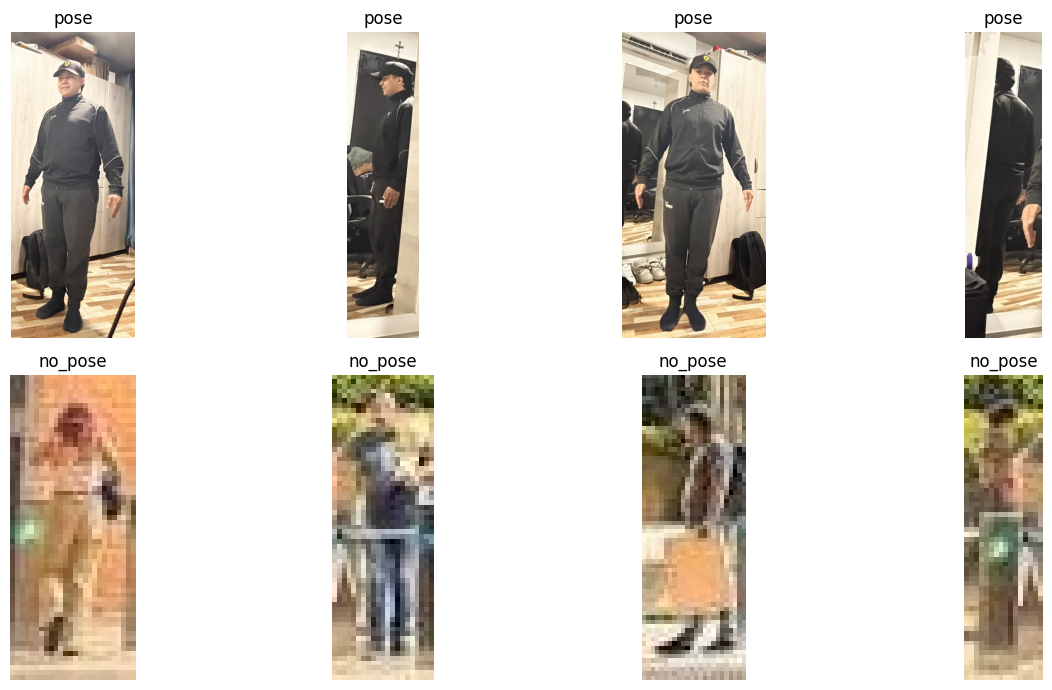

In [8]:

# SESIÓN 7.4: RESUMEN DE RECORTES


for conjunto in ["train", "val", "test"]:

    print(f"\n{conjunto.upper()}")

    for clase in ["pose", "no_pose"]:

        carpeta = CROP_DIR / conjunto / clase
        recortes = obtener_imagenes(carpeta)

        print(f"{clase}: {len(recortes)} recortes")

# SESIÓN 7.5: VISUALIZAR RECORTES


fig, axes = plt.subplots(2, 4, figsize=(14, 7))

clases = ["pose", "no_pose"]

for fila, clase in enumerate(clases):

    carpeta = CROP_DIR / "train" / clase
    imagenes = obtener_imagenes(carpeta)

    cantidad = min(4, len(imagenes))

    for columna in range(4):

        ax = axes[fila, columna]
        ax.axis("off")

        if columna < cantidad:

            with Image.open(imagenes[columna]) as img:
                ax.imshow(img.convert("RGB"))

            ax.set_title(clase)

plt.tight_layout()
plt.show()



Imágenes negativas sin personas detectadas:
84


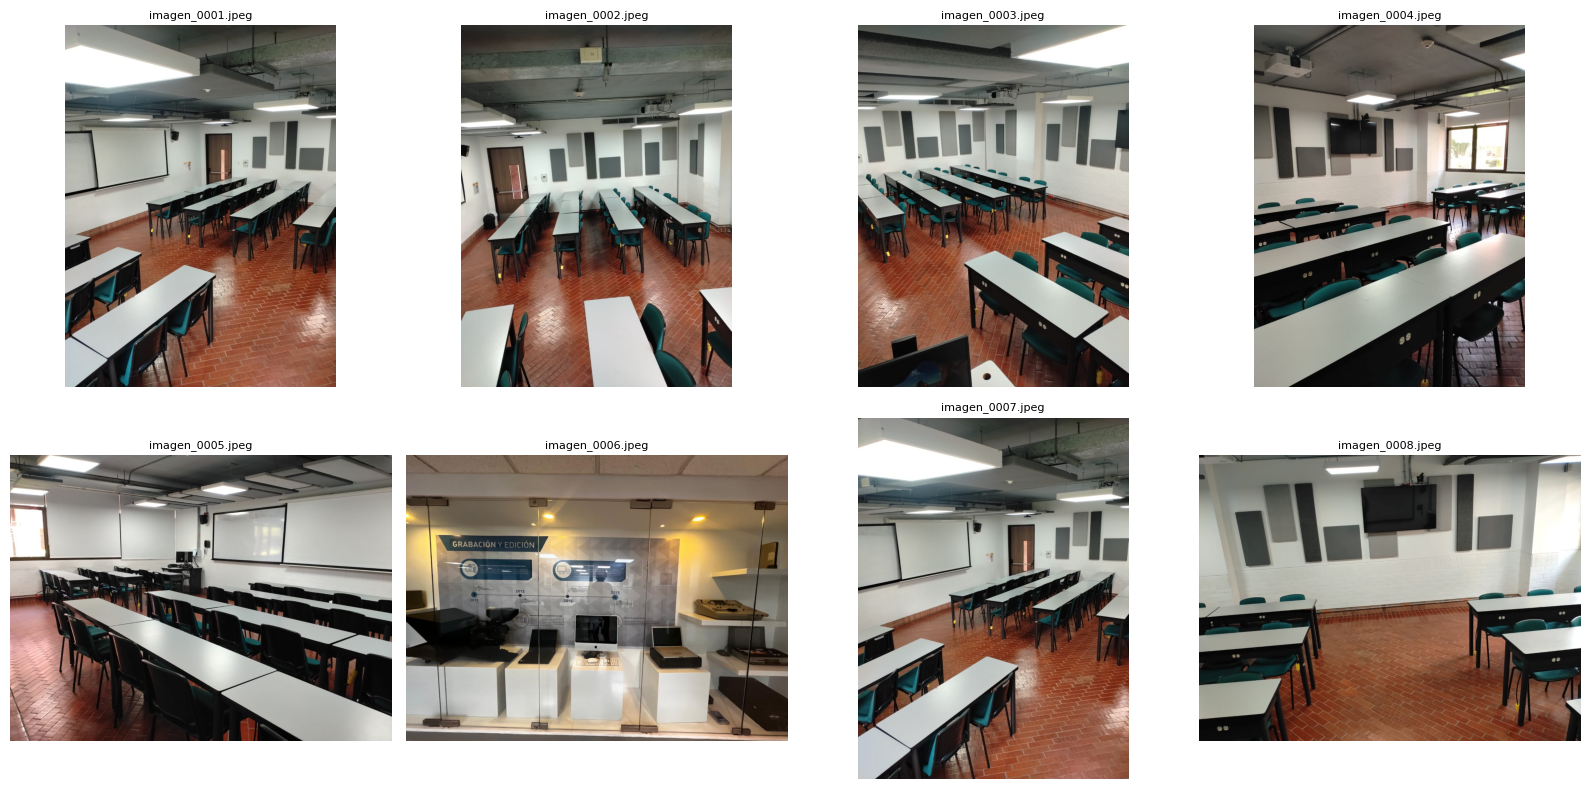

Recortes negativos encontrados: 64


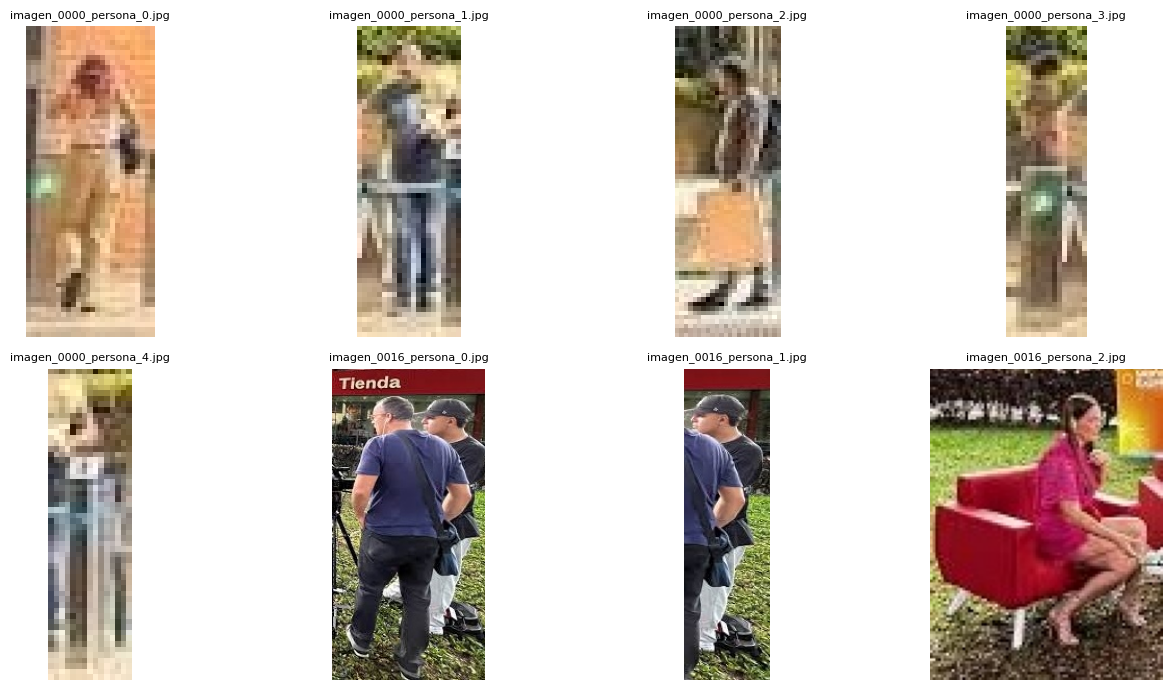

In [9]:

# SESIÓN 8.1: REVISAR NEGATIVOS SIN DETECCIÓN

registro = pd.read_csv(registro_path)

sin_persona = registro[
    (registro["clase_real"] == "no_pose") &
    (registro["personas_detectadas"] == 0)
]

print("Imágenes negativas sin personas detectadas:")
print(len(sin_persona))

# Mostrar hasta 8 imágenes
muestra = sin_persona.head(8)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, (_, fila) in zip(axes, muestra.iterrows()):

    ruta = fila["imagen"]

    with Image.open(ruta) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(Path(ruta).name, fontsize=8)
    ax.axis("off")

for ax in axes[len(muestra):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# SESIÓN 8.2: REVISAR PERSONAS NO BAILANDO

imagenes_negativas = obtener_imagenes(
    CROP_DIR / "train" / "no_pose"
)

print("Recortes negativos encontrados:", len(imagenes_negativas))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for ax, ruta in zip(axes, imagenes_negativas[:8]):

    with Image.open(ruta) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(ruta.name, fontsize=8)
    ax.axis("off")

for ax in axes[min(8, len(imagenes_negativas)):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [22]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(degrees=10),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Transformaciones configuradas.")


Transformaciones configuradas.


In [23]:
class DancePoseDataset(Dataset):

    def __init__(self, carpeta, transform=None):

        self.carpeta = Path(carpeta)
        self.transform = transform

        self.clases = {
            "no_pose": 0,
            "pose": 1
        }

        self.samples = []

        for nombre_clase, etiqueta in self.clases.items():

            carpeta_clase = self.carpeta / nombre_clase

            imagenes = obtener_imagenes(carpeta_clase)

            for imagen in imagenes:
                self.samples.append((imagen, etiqueta))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):

        ruta, etiqueta = self.samples[index]

        with Image.open(ruta) as img:
            imagen = img.convert("RGB")

        if self.transform:
            imagen = self.transform(imagen)

        return imagen, etiqueta


# Crear datasets
train_dataset = DancePoseDataset(
    CROP_DIR / "train",
    train_transform
)

val_dataset = DancePoseDataset(
    CROP_DIR / "val",
    eval_transform
)

test_dataset = DancePoseDataset(
    CROP_DIR / "test",
    eval_transform
)

print("TRAIN:", len(train_dataset))
print("VALIDACIÓN:", len(val_dataset))
print("TEST:", len(test_dataset))


TRAIN: 565
VALIDACIÓN: 109
TEST: 121


clases


In [24]:

def contar_clases(dataset):

    etiquetas = [etiqueta for _, etiqueta in dataset.samples]

    conteo = Counter(etiquetas)

    return {
        "no_pose": conteo.get(0, 0),
        "pose": conteo.get(1, 0)
    }


for nombre, dataset in [
    ("TRAIN", train_dataset),
    ("VALIDACIÓN", val_dataset),
    ("TEST", test_dataset)
]:

    print(f"\n{nombre}")
    print(contar_clases(dataset))



TRAIN
{'no_pose': 64, 'pose': 501}

VALIDACIÓN
{'no_pose': 1, 'pose': 108}

TEST
{'no_pose': 12, 'pose': 109}


In [15]:

train_labels = [
    etiqueta for _, etiqueta in train_dataset.samples
]

class_counts = Counter(train_labels)

class_weights = {
    clase: 1.0 / cantidad
    for clase, cantidad in class_counts.items()
}

sample_weights = [
    class_weights[etiqueta]
    for etiqueta in train_labels
]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders creados correctamente.")


DataLoaders creados correctamente.


**Arquitectura CNN** Y Mobilnetv2-pre

In [21]:

try:
    modelo_cnn = models.mobilenet_v2(
        weights=models.MobileNet_V2_Weights.DEFAULT
    )
    print("Pesos preentrenados cargados correctamente.")

except Exception as error:
    print("No se pudieron descargar los pesos preentrenados.")
    print("Detalle:", error)
    raise

# Congelar las capas convolucionales
for parametro in modelo_cnn.features.parameters():
    parametro.requires_grad = False

# Reemplazar clasificador original
numero_entradas = modelo_cnn.classifier[1].in_features

modelo_cnn.classifier = nn.Sequential(
    nn.Dropout(p=0.40),
    nn.Linear(numero_entradas, 128),
    nn.ReLU(),
    nn.Dropout(p=0.30),
    nn.Linear(128, 2)
)

modelo_cnn = modelo_cnn.to(DEVICE)

print("\nArquitectura CNN creada.")
print("Dispositivo:", DEVICE)
print("Clases de salida: 2")
print(modelo_cnn.classifier)


Pesos preentrenados cargados correctamente.

Arquitectura CNN creada.
Dispositivo: cuda
Clases de salida: 2
Sequential(
  (0): Dropout(p=0.4, inplace=False)
  (1): Linear(in_features=1280, out_features=128, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=128, out_features=2, bias=True)
)


ENTRENAMIENTO DEL **CNN** **PERSONA**

In [18]:


conteo_train = contar_clases(train_dataset)

cantidad_negativas = conteo_train["no_pose"]
cantidad_positivas = conteo_train["pose"]

total_train = cantidad_negativas + cantidad_positivas

# Pesos inversamente proporcionales a la frecuencia
pesos_clases = torch.tensor(
    [
        total_train / (2 * cantidad_negativas),
        total_train / (2 * cantidad_positivas)
    ],
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.CrossEntropyLoss(
    weight=pesos_clases
)

optimizer = optim.AdamW(
    modelo_cnn.classifier.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Pesos de las clases:", pesos_clases)
print("Optimizador:", optimizer)
print("Función de pérdida configurada.")


Pesos de las clases: tensor([4.4141, 0.5639], device='cuda:0')
Optimizador: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)
Función de pérdida configurada.


In [19]:


def ejecutar_epoca(modelo, loader, entrenamiento=False):

    if entrenamiento:
        modelo.train()
        # Mantener congelado BatchNorm de las características
        modelo.features.eval()
    else:
        modelo.eval()

    perdida_total = 0.0
    predicciones = []
    etiquetas_reales = []

    for imagenes, etiquetas in loader:

        imagenes = imagenes.to(
            DEVICE,
            non_blocking=True
        )

        etiquetas = etiquetas.to(
            DEVICE,
            non_blocking=True
        )

        if entrenamiento:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(entrenamiento):

            salidas = modelo(imagenes)

            perdida = criterion(
                salidas,
                etiquetas
            )

            if entrenamiento:
                perdida.backward()
                optimizer.step()

        perdida_total += perdida.item() * imagenes.size(0)

        predichas = torch.argmax(
            salidas,
            dim=1
        )

        predicciones.extend(
            predichas.detach().cpu().numpy()
        )

        etiquetas_reales.extend(
            etiquetas.detach().cpu().numpy()
        )

    perdida_media = perdida_total / len(loader.dataset)

    exactitud = accuracy_score(
        etiquetas_reales,
        predicciones
    )

    return perdida_media, exactitud


print("Funciones de entrenamiento creadas.")


Funciones de entrenamiento creadas.


Entenamiento


In [20]:


EPOCHS = 25
PATIENCE = 5

historial = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

mejor_val_loss = float("inf")
mejor_estado = copy.deepcopy(modelo_cnn.state_dict())
epocas_sin_mejora = 0

for epoca in range(EPOCHS):

    train_loss, train_acc = ejecutar_epoca(
        modelo_cnn,
        train_loader,
        entrenamiento=True
    )

    val_loss, val_acc = ejecutar_epoca(
        modelo_cnn,
        val_loader,
        entrenamiento=False
    )

    scheduler.step(val_loss)

    historial["train_loss"].append(train_loss)
    historial["val_loss"].append(val_loss)

    historial["train_acc"].append(train_acc)
    historial["val_acc"].append(val_acc)

    print(
        f"Época [{epoca + 1}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc:.4f} "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc:.4f}"
    )

    if val_loss < mejor_val_loss:

        mejor_val_loss = val_loss
        mejor_estado = copy.deepcopy(
            modelo_cnn.state_dict()
        )

        epocas_sin_mejora = 0

    else:
        epocas_sin_mejora += 1

    if epocas_sin_mejora >= PATIENCE:

        print("\nDetención temprana activada.")
        break


# Recuperar los mejores pesos
modelo_cnn.load_state_dict(mejor_estado)

print("\nEntrenamiento terminado.")
print("Mejor pérdida de validación:", mejor_val_loss)


Época [1/25] | Train Loss: 0.2495 | Train Acc: 0.6690 | Val Loss: 0.6205 | Val Acc: 0.7339
Época [2/25] | Train Loss: 0.0692 | Train Acc: 0.9434 | Val Loss: 0.1528 | Val Acc: 0.9633
Época [3/25] | Train Loss: 0.0395 | Train Acc: 0.9735 | Val Loss: 0.1262 | Val Acc: 0.9633
Época [4/25] | Train Loss: 0.0321 | Train Acc: 0.9699 | Val Loss: 0.0992 | Val Acc: 0.9725
Época [5/25] | Train Loss: 0.0251 | Train Acc: 0.9788 | Val Loss: 0.0984 | Val Acc: 0.9725
Época [6/25] | Train Loss: 0.0281 | Train Acc: 0.9770 | Val Loss: 0.0703 | Val Acc: 0.9817
Época [7/25] | Train Loss: 0.0104 | Train Acc: 0.9894 | Val Loss: 0.0606 | Val Acc: 0.9908
Época [8/25] | Train Loss: 0.0130 | Train Acc: 0.9947 | Val Loss: 0.0543 | Val Acc: 0.9817
Época [9/25] | Train Loss: 0.0271 | Train Acc: 0.9770 | Val Loss: 0.0420 | Val Acc: 0.9908
Época [10/25] | Train Loss: 0.0195 | Train Acc: 0.9805 | Val Loss: 0.0836 | Val Acc: 0.9908
Época [11/25] | Train Loss: 0.0163 | Train Acc: 0.9894 | Val Loss: 0.0569 | Val Acc: 0.99

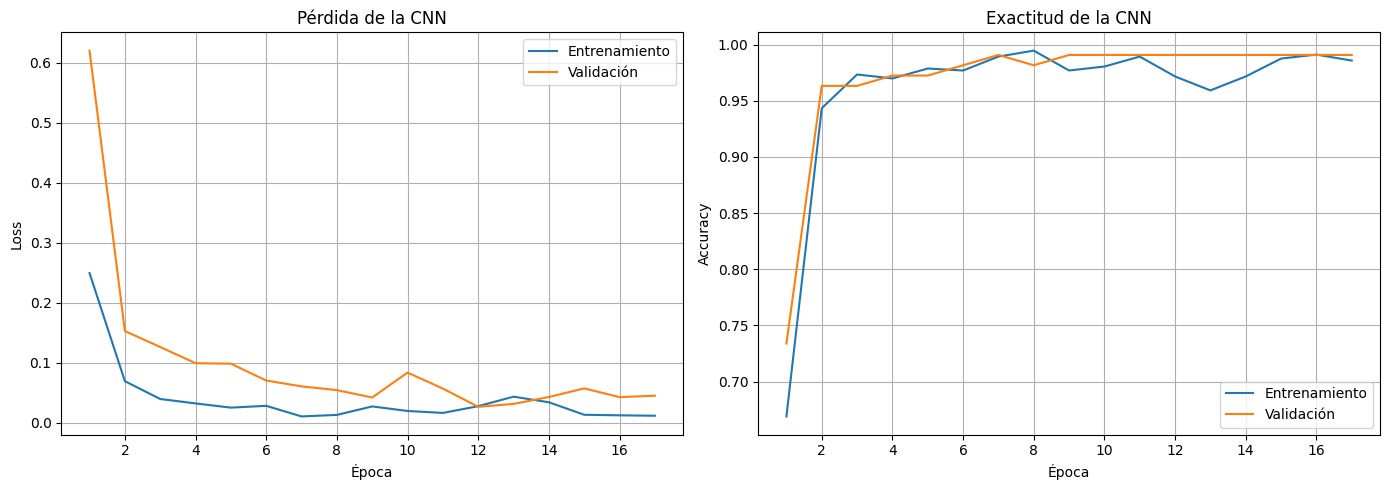

In [25]:
epocas = range(1, len(historial["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pérdida
axes[0].plot(
    epocas,
    historial["train_loss"],
    label="Entrenamiento"
)

axes[0].plot(
    epocas,
    historial["val_loss"],
    label="Validación"
)

axes[0].set_title("Pérdida de la CNN")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Exactitud
axes[1].plot(
    epocas,
    historial["train_acc"],
    label="Entrenamiento"
)

axes[1].plot(
    epocas,
    historial["val_acc"],
    label="Validación"
)

axes[1].set_title("Exactitud de la CNN")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


REPORTE DE CLASIFICACIÓN
                  precision    recall  f1-score   support

No pose de danza       0.00      0.00      0.00        12
   Pose de danza       0.90      0.98      0.94       109

        accuracy                           0.88       121
       macro avg       0.45      0.49      0.47       121
    weighted avg       0.81      0.88      0.85       121



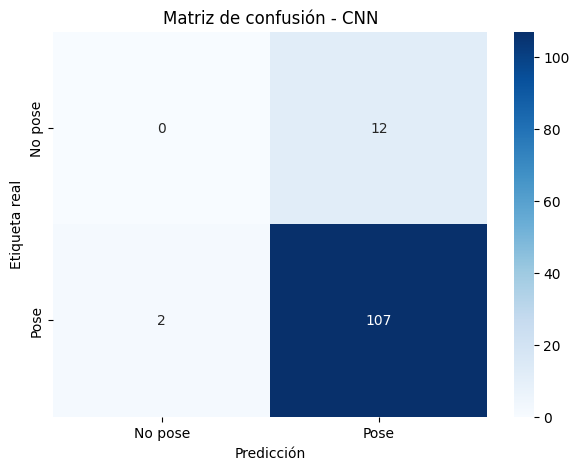

In [26]:
modelo_cnn.eval()

predicciones_test = []
etiquetas_test = []

with torch.no_grad():

    for imagenes, etiquetas in test_loader:

        imagenes = imagenes.to(DEVICE)

        salidas = modelo_cnn(imagenes)

        predichas = torch.argmax(
            salidas,
            dim=1
        )

        predicciones_test.extend(
            predichas.cpu().numpy()
        )

        etiquetas_test.extend(
            etiquetas.numpy()
        )

print("REPORTE DE CLASIFICACIÓN")
print("==============================")

print(
    classification_report(
        etiquetas_test,
        predicciones_test,
        labels=[0, 1],
        target_names=["No pose de danza", "Pose de danza"],
        zero_division=0
    )
)

matriz = confusion_matrix(
    etiquetas_test,
    predicciones_test,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No pose", "Pose"],
    yticklabels=["No pose", "Pose"]
)

plt.xlabel("Predicción")
plt.ylabel("Etiqueta real")
plt.title("Matriz de confusión - CNN")
plt.show()


In [ ]:
CNN_MODEL_PATH = BASE_DIR / "cnn_filtro_pose.pth"

torch.save(
    {
        "model_state_dict": modelo_cnn.state_dict(),
        "class_names": {
            0: "no_pose",
            1: "pose"
        },
        "img_size": IMG_SIZE,
        "architecture": "MobileNetV2",
        "normalization_mean": [0.485, 0.456, 0.406],
        "normalization_std": [0.229, 0.224, 0.225]
    },
    CNN_MODEL_PATH
)

print("Modelo guardado correctamente.")
print("Ubicación:", CNN_MODEL_PATH)
